In [9]:
%run ./dataset.ipynb
%run ./model.ipynb

Metadata path: E:\Shortcutscope\archive\waterbird_complete95_forest2water2\metadata.csv
Dataset shape: (11788, 6)
Columns: ['img_id', 'img_filename', 'y', 'split', 'place', 'place_filename']

First five rows:
   img_id                                                   img_filename  y  split  place                 place_filename
0       1  001.Black_footed_Albatross/Black_Footed_Albatross_0046_18.jpg  1      2      1          /o/ocean/00002178.jpg
1       2  001.Black_footed_Albatross/Black_Footed_Albatross_0009_34.jpg  1      0      1   /l/lake/natural/00000065.jpg
2       3  001.Black_footed_Albatross/Black_Footed_Albatross_0002_55.jpg  1      2      0  /b/bamboo_forest/00000131.jpg
3       4  001.Black_footed_Albatross/Black_Footed_Albatross_0074_59.jpg  1      0      1          /o/ocean/00001268.jpg
4       5  001.Black_footed_Albatross/Black_Footed_Albatross_0014_89.jpg  1      0      1          /o/ocean/00003147.jpg

Split column data type:
int64

Actual split values:
split
2    5

In [10]:

# ============================================================
# LOAD ALL THREE TRAINED MODELS
# ============================================================

BASELINE_PATH = "frozen_experiment_2026-10-14/models/baseline_cnn.pt"
WEIGHTED_PATH = "frozen_experiment_2026-10-14/models/weighted_cnn.pt"
BALANCED_PATH = "models/balanced_sampling_cnn.pt"

def load_frozen_model(path):
    model = ShortcutScopeCNN(num_classes=2).to(DEVICE)

    state_dict = torch.load(
        path,
        map_location=DEVICE,
        weights_only=True
    )

    model.load_state_dict(state_dict)
    model.eval()
    return model


baseline_model = load_frozen_model(BASELINE_PATH)
weighted_model = load_frozen_model(WEIGHTED_PATH)
balanced_model = load_frozen_model(BALANCED_PATH)

print("All three models loaded successfully.")


All three models loaded successfully.


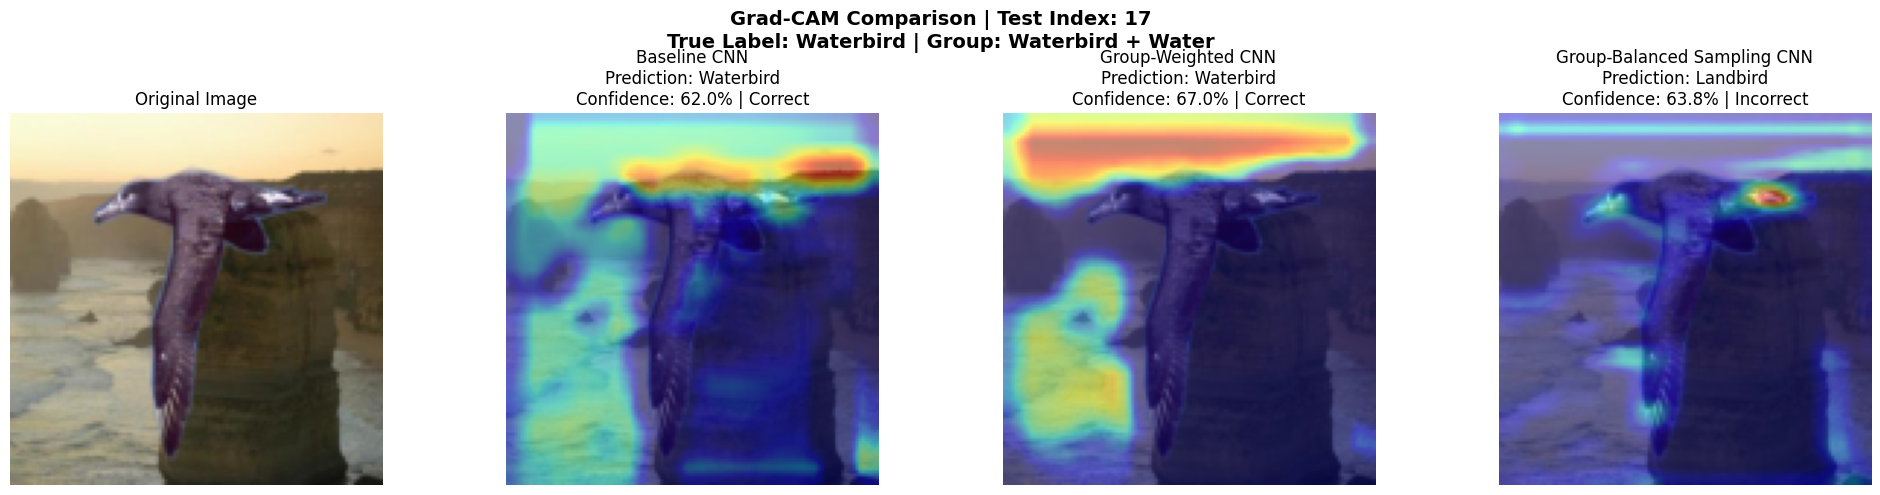

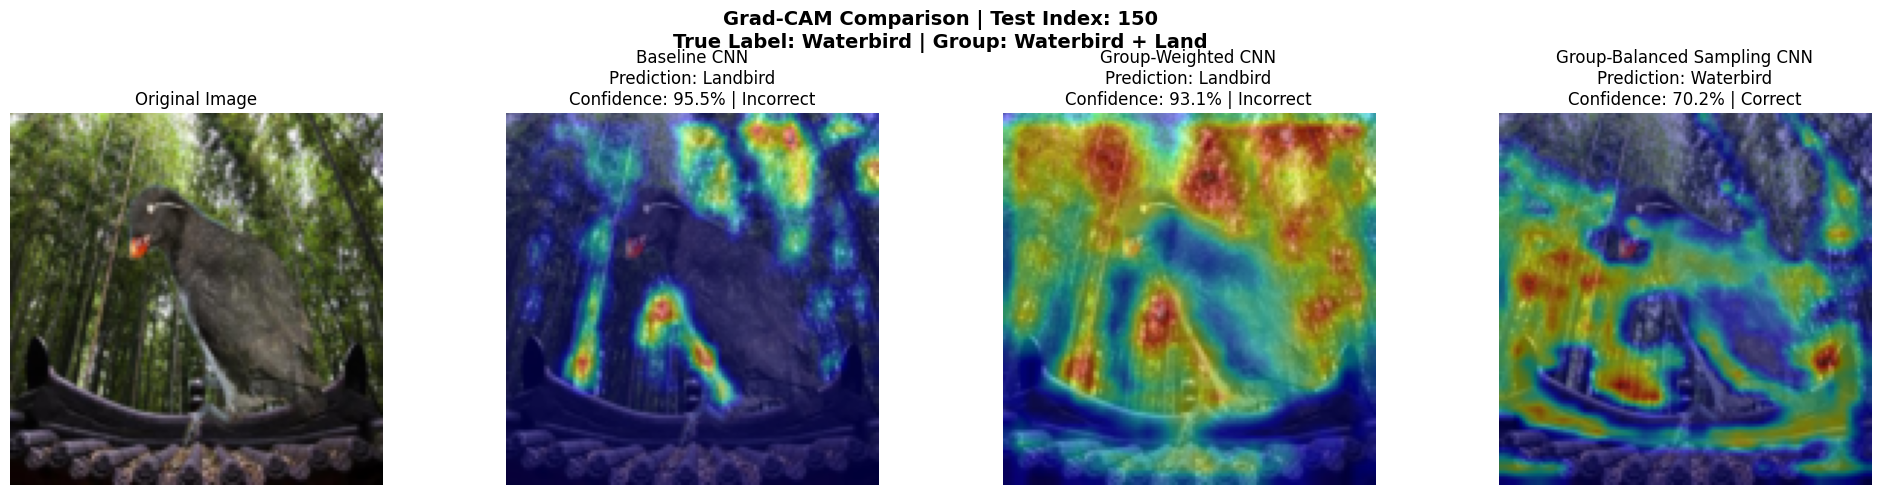

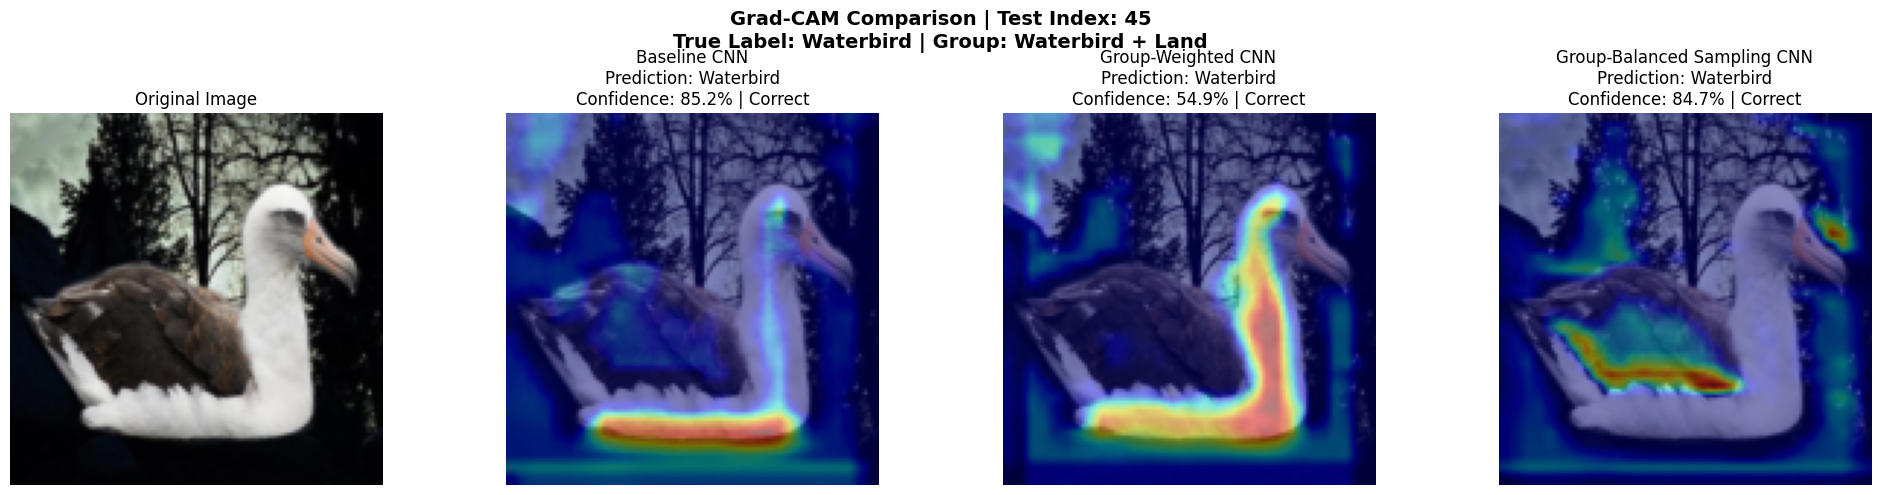

In [11]:
display_gradcam(17)
display_gradcam(150)
display_gradcam(45)

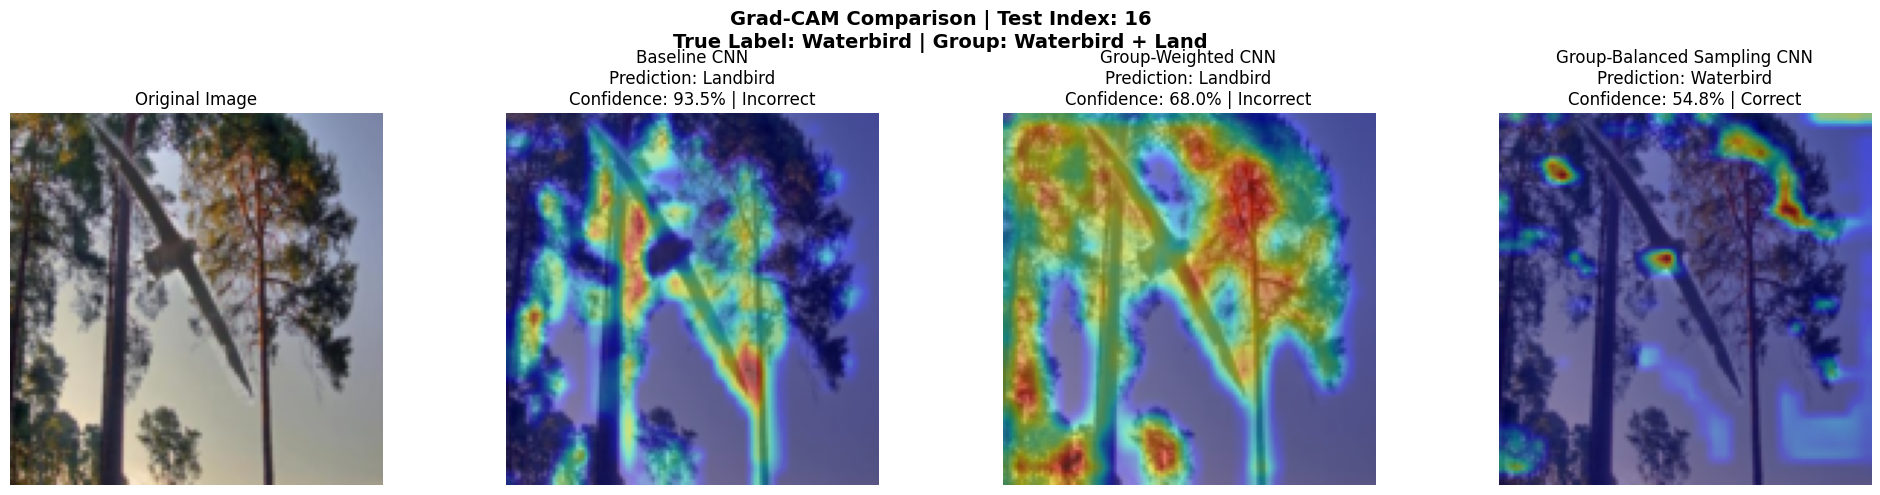

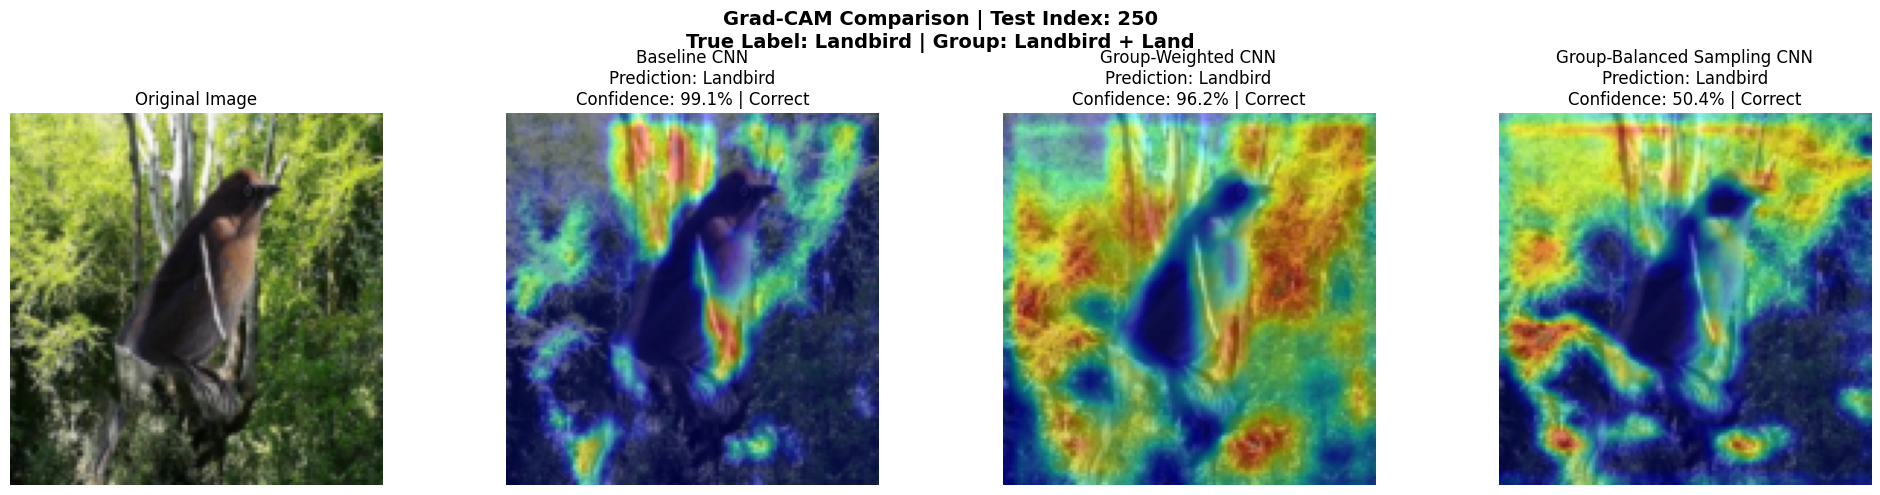

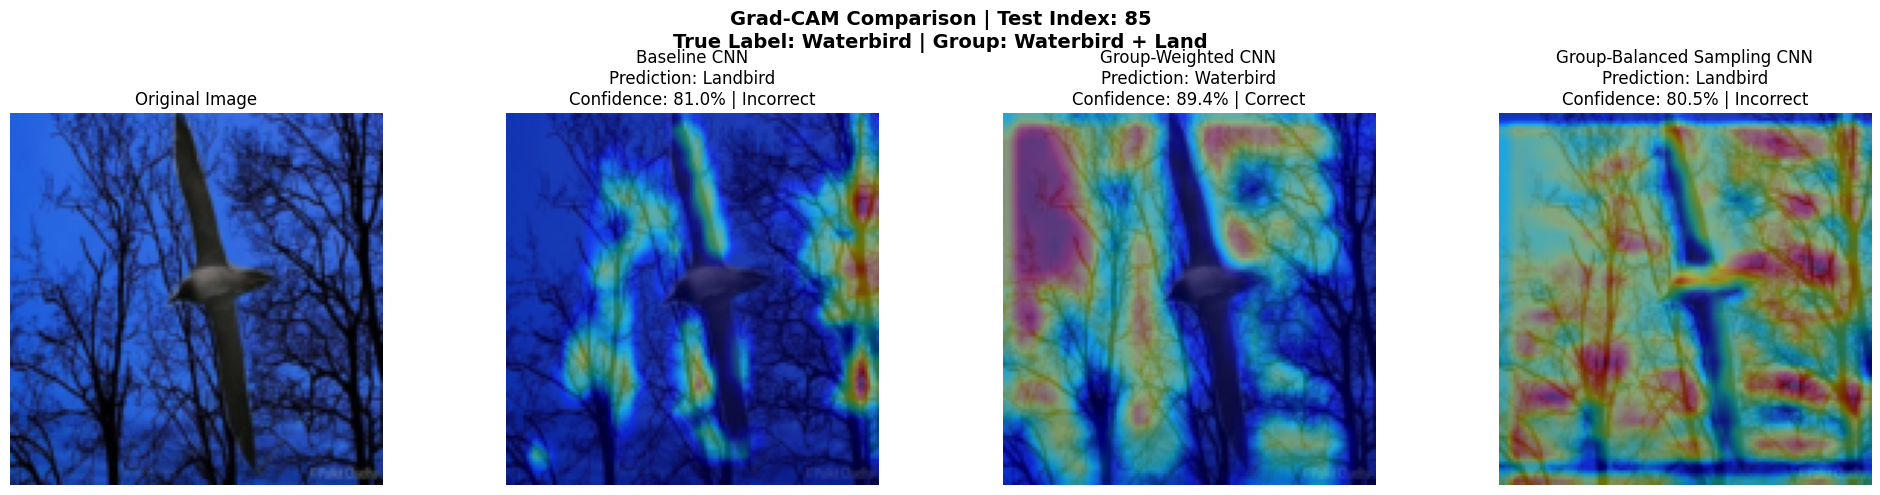

In [13]:

# ============================================================
# SHORTCUTSCOPE: GRAD-CAM COMPARISON OF ALL THREE MODELS
# ============================================================

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ------------------------------------------------------------
# 3. GENERATE GRAD-CAM
# ------------------------------------------------------------

def generate_gradcam(model, image_tensor, target_class=None):
    model.eval()

    activations = {}
    gradients = {}

    # Final convolutional block's first layer
    target_layer = model.block3[0]

    def forward_hook(module, inputs, output):
        activations["value"] = output

        output.register_hook(
            lambda grad: gradients.update({"value": grad})
        )

    hook_handle = target_layer.register_forward_hook(forward_hook)

    model.zero_grad(set_to_none=True)
    input_tensor = image_tensor.unsqueeze(0).to(DEVICE)

    try:
        # Gradients must remain enabled for Grad-CAM
        with torch.enable_grad():
            logits = model(input_tensor)
            probabilities = torch.softmax(logits, dim=1)

            # Explain the model's predicted class by default
            if target_class is None:
                target_class = logits.argmax(dim=1).item()

            score = logits[0, target_class]
            score.backward()

            feature_maps = activations["value"]
            grads = gradients["value"]

            # Importance weights for each feature map
            weights = grads.mean(dim=(2, 3), keepdim=True)

            # Weighted combination of feature maps
            cam = F.relu(
                (weights * feature_maps).sum(dim=1, keepdim=True)
            )

            cam = F.interpolate(
                cam,
                size=image_tensor.shape[1:],
                mode="bilinear",
                align_corners=False
            )

            cam = cam[0, 0].detach().cpu().numpy()
            cam = cam - cam.min()
            cam = cam / (cam.max() + 1e-8)

            probabilities = probabilities[0].detach().cpu().numpy()

        return cam, probabilities, target_class

    finally:
        hook_handle.remove()
        model.zero_grad(set_to_none=True)


# ------------------------------------------------------------
# 4. IMAGE NORMALIZATION VALUES
# ------------------------------------------------------------

MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


# ------------------------------------------------------------
# 5. DISPLAY ALL THREE MODELS ON THE SAME IMAGE
# ------------------------------------------------------------

def display_gradcam(index):
    # test_dataset returns (image, label, group_id)
    image_tensor, true_label, group_id = test_dataset[index]

    # Convert normalized tensor back to RGB for display
    image = image_tensor.detach().cpu() * STD + MEAN
    image = image.clamp(0, 1).permute(1, 2, 0).numpy()

    models = [
        ("Baseline CNN", baseline_model),
        ("Group-Weighted CNN", weighted_model),
        ("Group-Balanced Sampling CNN", balanced_model)
    ]

    class_names = ["Landbird", "Waterbird"]

    group_names = {
        0: "Landbird + Land",
        1: "Landbird + Water",
        2: "Waterbird + Land",
        3: "Waterbird + Water"
    }

    # One original image + three model explanations
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(image)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    for ax, (model_name, model) in zip(axes[1:], models):
        cam, probabilities, predicted_class = generate_gradcam(
            model,
            image_tensor
        )

        ax.imshow(image)
        ax.imshow(
            cam,
            cmap="jet",
            alpha=0.45,
            vmin=0,
            vmax=1
        )

        confidence = probabilities[predicted_class]

        # Mark correct and incorrect predictions
        status = (
            "Correct"
            if predicted_class == int(true_label)
            else "Incorrect"
        )

        ax.set_title(
            f"{model_name}\n"
            f"Prediction: {class_names[predicted_class]}\n"
            f"Confidence: {confidence:.1%} | {status}"
        )
        ax.axis("off")

    fig.suptitle(
        f"Grad-CAM Comparison | Test Index: {index}\n"
        f"True Label: {class_names[int(true_label)]} | "
        f"Group: {group_names[int(group_id)]}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 6. VISUALIZE THE SAME TEST EXAMPLES
# ------------------------------------------------------------

display_gradcam(16)
display_gradcam(250)
display_gradcam(85)
